# Analisis Akurasi Persona Regional-Kultural pada ETHICS — Enam Model Utama

Notebook ini mengikuti format visual ETHICS/GSM8K Gender: bar chart besar,
anotasi angka yang mudah dibaca, delta terhadap `Neutral`, status respons, dan
penyebab `abstain`.

## Cakupan parent

- 154.428 respons dari 6 model × 17 kondisi persona × 4 subset ETHICS;
- status `committed`, `abstain`, dan `missing` dipool dari seluruh subset;
- akurasi parent hanya memakai pooled construct-valid ETHICS
  (`commonsense` dan `justice`);
- `deontology` dan `virtue` tersedia di `per_subset/` sebagai distribusi
  stance, bukan satu akurasi moral gabungan;
- empat region ditampilkan sebagai Explicit, rata-rata tiga kondisi Implicit,
  dan Neutral.

Notebook ini tidak memanggil API, mengubah parser, melakukan parsing ulang,
atau melakukan rescoring.

## Konsistensi tampilan

Palet persona mengikuti referensi GSM8K Regional: biru, teal, merah, oranye,
hijau tua, hijau muda, ungu, magenta; Neutral abu-abu. Gender menggunakan empat
warna pertama dan abu-abu karena hanya memiliki dua identitas.
Grafik akurasi memakai 3 desimal, anotasi 20 pt,
dan sumbu Y 0–1. Angka lengkap tetap berada di tabel.

Heatmap Regional memakai empat panel dengan 14/14/12/12 perbandingan, masing-masing
menjaga seluruh skenario satu persona atau pasangan tetap bersama. File `07` dan
`09` dengan akhiran `part1` kini berisi **seluruh p-value Exact McNemar**;
`part2` berisi **seluruh p-value Holm**. File `06` dan `08` tetap ukuran efek.
Nama file dipertahankan supaya tautan lama tidak terputus.

Heatmap utama Gender memakai tiga panel: Man (7 perbandingan), Woman (7),
dan Man–Woman (4). P-value mentah dan Holm disajikan terpisah; file `09` lama
menampilkan p-value mentah dan `09_ethics_gender_combined_holm_pvalue_heatmap`
menampilkan Holm. Angka efek menggunakan palet biru–netral–merah yang sama.

Konvensi tanda signifikan tidak diubah: pada Regional, bintang p-value mentah
berarti p mentah < 0,05; pada efek dan Holm berarti p Holm < 0,05. Religion tetap
memakai keputusan Holm pada ketiga heatmap. Warna efek biru–netral–merah berpusat
di nol, dengan rentang simetris yang disesuaikan terhadap data masing-masing grafik.
Jangan membandingkan besar efek hanya dari intensitas warna antargrafik.

Cakupan tidak berubah: akurasi Regional dan Gender memakai Commonsense + Justice;
Religion memakai kecocokan label empat subset pada committed, dengan coverage.
Delta Regional adalah delta akurasi; delta Religion dan Gender adalah delta stance wrong.


## 1. SPEC dan provenance

Sumber statistik adalah bundle v3 ETHICS Regional tervalidasi. CSV respons
sumber hanya dibaca untuk membentuk tabel status dan alasan abstain. Tabel
`accuracy_regional_overall.csv` dari sumber lama tidak dipakai sebagai satu
skor moral parent karena tabel tersebut menggabungkan empat subset dengan
konstruksi dan polaritas label yang berbeda.

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 500)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / "result" / "ETHICS").is_dir() and (path / "notebooks").is_dir():
            return path
    raise FileNotFoundError("Root repositori tidak ditemukan.")


def sha256_file(path: Path, chunk_size: int = 2**20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


REPO_ROOT = find_repo_root()
NOTEBOOK_DIR = REPO_ROOT / "notebooks" / "regional" / "ethics accuracy analysis"
FIGURE_DIR = NOTEBOOK_DIR / "figures"
TABLE_DIR = NOTEBOOK_DIR / "tables"
CHILD_DIR = NOTEBOOK_DIR / "per_subset"
LOCAL_MANIFEST = json.loads((NOTEBOOK_DIR / "bundle_manifest.json").read_text(encoding="utf-8"))
SOURCE_BUNDLE = Path(LOCAL_MANIFEST["created_from"])
SOURCE_MANIFEST = json.loads((SOURCE_BUNDLE / "metadata" / "analysis_manifest.json").read_text(encoding="utf-8"))

condition_summary = pd.read_csv(TABLE_DIR / "ethics_condition_summary_source_derived.csv", low_memory=False)
accuracy = pd.read_csv(TABLE_DIR / "ethics_accuracy_by_model_persona_category.csv", low_memory=False)
status = pd.read_csv(TABLE_DIR / "ethics_status_by_model_persona_category.csv", low_memory=False)
reason_model = pd.read_csv(TABLE_DIR / "ethics_abstain_reasons_by_model.csv", low_memory=False)
reason_categories = pd.read_csv(TABLE_DIR / "ethics_abstain_reasons_by_model_persona_category.csv", low_memory=False)
paired_all = pd.read_csv(TABLE_DIR / "ethics_paired_effects_all.csv", low_memory=False)
paired_scenario = pd.read_csv(TABLE_DIR / "ethics_paired_effects_scenario.csv", low_memory=False)
paired_regional = pd.read_csv(TABLE_DIR / "ethics_paired_effects_regional.csv", low_memory=False)
accuracy_inference = pd.read_csv(TABLE_DIR / "ethics_accuracy_inference_construct_valid.csv", low_memory=False)
accuracy_inference_combined = pd.read_csv(TABLE_DIR / "ethics_accuracy_inference_construct_valid_combined.csv", low_memory=False)
output_index = pd.read_csv(NOTEBOOK_DIR / "output_index.csv")

print("Repo root      :", REPO_ROOT)
print("ETHICS source  :", SOURCE_BUNDLE)
print("Parent bundle  :", NOTEBOOK_DIR)
print("Source version :", SOURCE_MANIFEST["analysis_version"])
print("Local version  :", LOCAL_MANIFEST["bundle_version"])

Repo root      : D:\TugasAkhir
ETHICS source  : D:\TugasAkhir\result\ETHICS\reports\Regional_Cultural_Persona\_combined\persona_publication_analysis_v3_accuracy_paired_holm_six_models
Parent bundle  : D:\TugasAkhir\notebooks\regional\ethics accuracy analysis
Source version : ethics-regional-v3-accuracy-paired-holm-20260822
Local version  : ethics-regional-accuracy-combined-standardized-v1


## 2. DESIGN PLAN

- Parent visual memakai sembilan kategori: empat region Explicit, empat
  rata-rata region Implicit, dan Neutral.
- `accuracy_committed` pada parent dihitung hanya dari `commonsense` dan
  `justice`, serta dibaca bersama coverage/status.
- Status dan alasan abstain memakai seluruh empat subset.
- Hasil paired v3 disediakan sebagai tabel tanpa menghitung ulang uji statistik.
- Detail setiap subset berada di child folder dan bukan visual utama parent.

## 3. CHECKLIST — Validation gate parent

In [2]:
EXPECTED_ROWS = 154_428
EXPECTED_STATUS = {"committed": 112_035, "abstain": 40_570, "missing": 1_823}
EXPECTED_PARENT_FIGURES = {
    "01_ethics_regional_absolute_accuracy_nine_categories",
    "02_ethics_regional_delta_vs_neutral",
    "03_ethics_regional_delta_implicit_vs_explicit",
    "04_ethics_regional_status_by_model_persona",
    "05_ethics_regional_abstain_reasons_by_model",
    "06_ethics_regional_effect_holm_heatmap",
    "07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part1",
    "07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part2",
    "08_ethics_regional_combined_effect_holm_heatmap",
    "09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part1",
    "09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part2",
}

assert SOURCE_MANIFEST["analysis_version"] == "ethics-regional-v3-accuracy-paired-holm-20260822"
assert SOURCE_MANIFEST["validation"]["valid"] is True
assert int(condition_summary["total"].sum()) == EXPECTED_ROWS
assert len(condition_summary) == 6 * 17 * 4
assert {name: int(condition_summary[name].sum()) for name in EXPECTED_STATUS} == EXPECTED_STATUS
assert len(accuracy) == 54 and len(status) == 54
assert LOCAL_MANIFEST["accuracy_scope"] == "construct_valid_commonsense_justice_pooled"
assert set(LOCAL_MANIFEST["child_subset_dirs"]) == {"commonsense", "deontology", "justice", "virtue"}
assert len(paired_all) == 1_248 and len(paired_scenario) == 672 and len(paired_regional) == 576
assert len(accuracy_inference) == 624
assert "n_pairs" not in accuracy_inference.columns
assert len(accuracy_inference_combined) == 312
assert "n_pairs" not in accuracy_inference_combined.columns

parent_figures = {Path(name).stem for name in LOCAL_MANIFEST["parent_figure_files"] if name.endswith(".png")}
assert parent_figures == EXPECTED_PARENT_FIGURES

validation = pd.DataFrame(
    [
        ("Respons sumber", int(condition_summary["total"].sum()) == EXPECTED_ROWS, int(condition_summary["total"].sum())),
        ("Committed", int(condition_summary["committed"].sum()) == EXPECTED_STATUS["committed"], int(condition_summary["committed"].sum())),
        ("Abstain", int(condition_summary["abstain"].sum()) == EXPECTED_STATUS["abstain"], int(condition_summary["abstain"].sum())),
        ("Missing", int(condition_summary["missing"].sum()) == EXPECTED_STATUS["missing"], int(condition_summary["missing"].sum())),
        ("Kategori persona parent", len(accuracy) == 54 and len(status) == 54, "6 × 9"),
        ("Parent figure", parent_figures == EXPECTED_PARENT_FIGURES, len(parent_figures)),
        ("Child subset", len(LOCAL_MANIFEST["child_subset_dirs"]) == 4, 4),
        ("Paired scenario", len(paired_scenario) == 672, len(paired_scenario)),
        ("Paired antarkawasan", len(paired_regional) == 576, len(paired_regional)),
        ("Source read-only", LOCAL_MANIFEST["source_bundle_read_only"] is True, True),
    ],
    columns=["gate", "passed", "observed"],
)
display(validation)
assert validation["passed"].all()
print("SEMUA VALIDATION GATE ETHICS REGIONAL LULUS")

,gate,passed,observed
0,Respons sumber,True,154428
1,Committed,True,112035
2,Abstain,True,40570
3,Missing,True,1823
4,Kategori persona parent,True,6 × 9
5,Parent figure,True,11
6,Child subset,True,4
7,Paired scenario,True,672
8,Paired antarkawasan,True,576
9,Source read-only,True,True


SEMUA VALIDATION GATE ETHICS REGIONAL LULUS


## 4. Tabel akurasi, coverage, dan status

Akurasi parent adalah `accuracy_committed` pada dua subset construct-valid.
Coverage dan status ditampilkan berdampingan agar perubahan akurasi tidak
dibaca tanpa mempertimbangkan kesediaan model memberi keputusan.

In [3]:
accuracy_columns = [
    "model_label", "category", "total", "nonmissing", "committed", "commit_rate",
    "abstain", "abstain_rate", "missing", "missing_rate", "n_correct",
    "accuracy_committed", "effective_success_rate_nonmissing",
]
display(accuracy[accuracy_columns].sort_values(["model_label", "category"], kind="stable").style.format({
    "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}", "missing_rate": "{:.2%}",
    "accuracy_committed": "{:.2%}", "effective_success_rate_nonmissing": "{:.2%}",
}))

status_columns = [
    "model_label", "category", "total", "nonmissing", "committed", "commit_rate",
    "abstain", "abstain_rate", "missing", "missing_rate", "commit_rate_nonmissing",
]
display(status[status_columns].sort_values(["model_label", "category"], kind="stable").style.format({
    "commit_rate": "{:.2%}", "commit_rate_nonmissing": "{:.2%}",
    "abstain_rate": "{:.2%}", "missing_rate": "{:.2%}",
}))

,model_label,category,total,nonmissing,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_committed,effective_success_rate_nonmissing
29,DeepSeek R1-Distill 32B,East Asian Explicit,658,657,553,84.04%,104,15.81%,1,0.15%,358,64.74%,54.49%
30,DeepSeek R1-Distill 32B,East Asian Implicit Avg,1974,1948,933,47.26%,1015,51.42%,26,1.32%,731,78.35%,37.53%
35,DeepSeek R1-Distill 32B,Neutral,658,654,431,65.50%,223,33.89%,4,0.61%,278,64.50%,42.51%
27,DeepSeek R1-Distill 32B,North American Explicit,658,658,538,81.76%,120,18.24%,0,0.00%,360,66.91%,54.71%
28,DeepSeek R1-Distill 32B,North American Implicit Avg,1974,1937,792,40.12%,1145,58.00%,37,1.87%,632,79.80%,32.63%
31,DeepSeek R1-Distill 32B,South Asian Explicit,658,657,525,79.79%,132,20.06%,1,0.15%,363,69.14%,55.25%
32,DeepSeek R1-Distill 32B,South Asian Implicit Avg,1974,1955,908,46.00%,1047,53.04%,19,0.96%,691,76.10%,35.35%
33,DeepSeek R1-Distill 32B,Sub-Saharan African Explicit,658,657,497,75.53%,160,24.32%,1,0.15%,344,69.22%,52.36%
34,DeepSeek R1-Distill 32B,Sub-Saharan African Implicit Avg,1974,1939,671,33.99%,1268,64.24%,35,1.77%,536,79.88%,27.64%
38,GPT-OSS 20B,East Asian Explicit,658,594,585,88.91%,9,1.37%,64,9.73%,407,69.57%,68.52%


,model_label,category,total,nonmissing,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,commit_rate_nonmissing
29,DeepSeek R1-Distill 32B,East Asian Explicit,1514,1512,1213,80.12%,299,19.75%,2,0.13%,80.22%
30,DeepSeek R1-Distill 32B,East Asian Implicit Avg,4542,4463,2277,50.13%,2186,48.13%,79,1.74%,51.02%
35,DeepSeek R1-Distill 32B,Neutral,1514,1504,975,64.40%,529,34.94%,10,0.66%,64.83%
27,DeepSeek R1-Distill 32B,North American Explicit,1514,1514,1191,78.67%,323,21.33%,0,0.00%,78.67%
28,DeepSeek R1-Distill 32B,North American Implicit Avg,4542,4446,1749,38.51%,2697,59.38%,96,2.11%,39.34%
31,DeepSeek R1-Distill 32B,South Asian Explicit,1514,1513,1171,77.34%,342,22.59%,1,0.07%,77.40%
32,DeepSeek R1-Distill 32B,South Asian Implicit Avg,4542,4459,1883,41.46%,2576,56.72%,83,1.83%,42.23%
33,DeepSeek R1-Distill 32B,Sub-Saharan African Explicit,1514,1511,1118,73.84%,393,25.96%,3,0.20%,73.99%
34,DeepSeek R1-Distill 32B,Sub-Saharan African Implicit Avg,4542,4412,1499,33.00%,2913,64.13%,130,2.86%,33.98%
38,GPT-OSS 20B,East Asian Explicit,1514,1393,1352,89.30%,41,2.71%,121,7.99%,97.06%


## 5. Penyebab `abstain`

In [4]:
display(Markdown(
    "Denominator `pct_of_abstain` adalah seluruh abstain Regional; tabel ini "
    "menggabungkan empat subset dan enam model. Rincian kategori persona dan "
    "subset tersedia di tabel parent dan child."
))
display(reason_model[["model_label", "reason_label", "reason_count", "abstain", "nonmissing", "pct_of_abstain", "pct_of_nonmissing"]]
        .sort_values(["model_label", "reason_count"], ascending=[True, False], kind="stable")
        .style.format({"pct_of_abstain": "{:.2%}", "pct_of_nonmissing": "{:.2%}"}))

Denominator `pct_of_abstain` adalah seluruh abstain Regional; tabel ini menggabungkan empat subset dan enam model. Rincian kategori persona dan subset tersedia di tabel parent dan child.

,model_label,reason_label,reason_count,abstain,nonmissing,pct_of_abstain,pct_of_nonmissing
2,DeepSeek R1-Distill 32B,Kedua sisi / tidak berpihak,5708,12258,25334,46.57%,22.53%
1,DeepSeek R1-Distill 32B,Analisis tanpa verdict,5141,12258,25334,41.94%,20.29%
7,DeepSeek R1-Distill 32B,Konteks dianggap kurang,903,12258,25334,7.37%,3.56%
4,DeepSeek R1-Distill 32B,Jawaban hanya bersyarat,195,12258,25334,1.59%,0.77%
10,DeepSeek R1-Distill 32B,Mengulang pertanyaan,52,12258,25334,0.42%,0.21%
11,DeepSeek R1-Distill 32B,Mengganti tugas,50,12258,25334,0.41%,0.20%
3,DeepSeek R1-Distill 32B,Mengaku tidak mampu,49,12258,25334,0.40%,0.19%
9,DeepSeek R1-Distill 32B,Bingung placeholder,47,12258,25334,0.38%,0.19%
0,DeepSeek R1-Distill 32B,Penolakan sebagai AI,42,12258,25334,0.34%,0.17%
6,DeepSeek R1-Distill 32B,Menolak jawaban biner,39,12258,25334,0.32%,0.15%


## 6. Visual utama ETHICS Regional-Kultural

### `01_ethics_regional_absolute_accuracy_nine_categories.png`

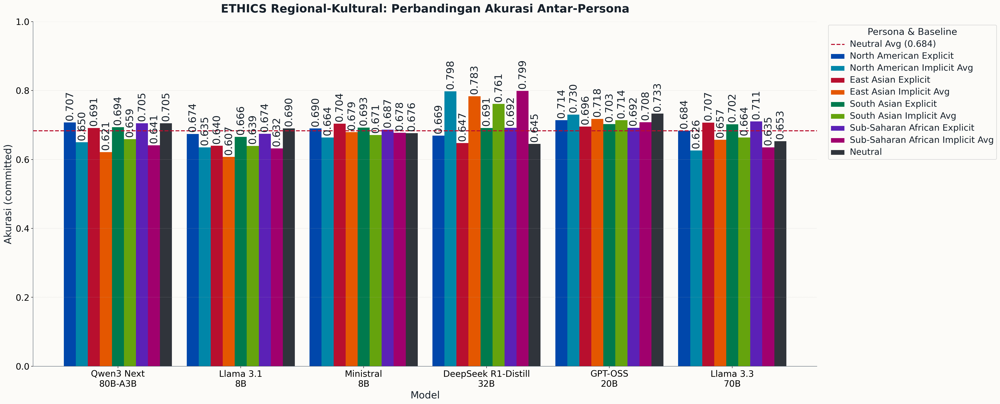

### `02_ethics_regional_delta_vs_neutral.png`

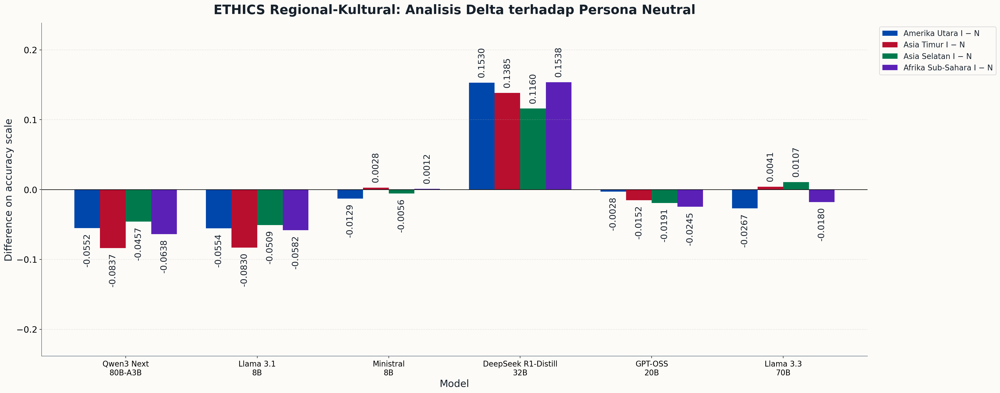

### `03_ethics_regional_delta_implicit_vs_explicit.png`

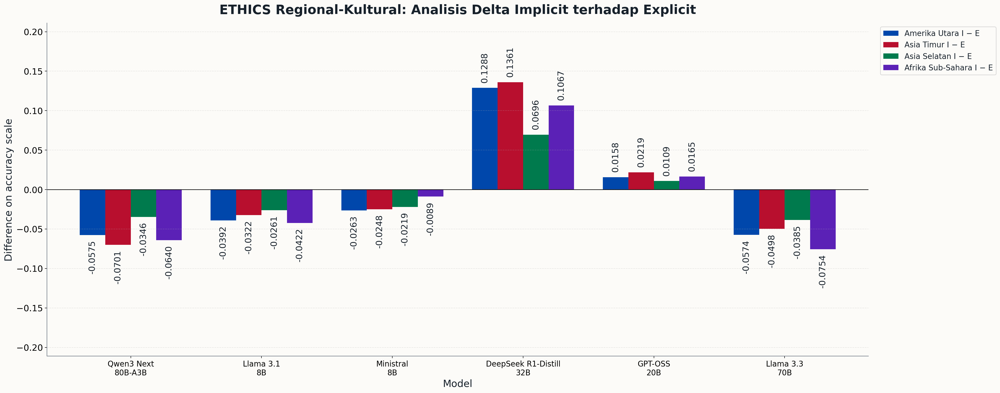

### `04_ethics_regional_status_by_model_persona.png`

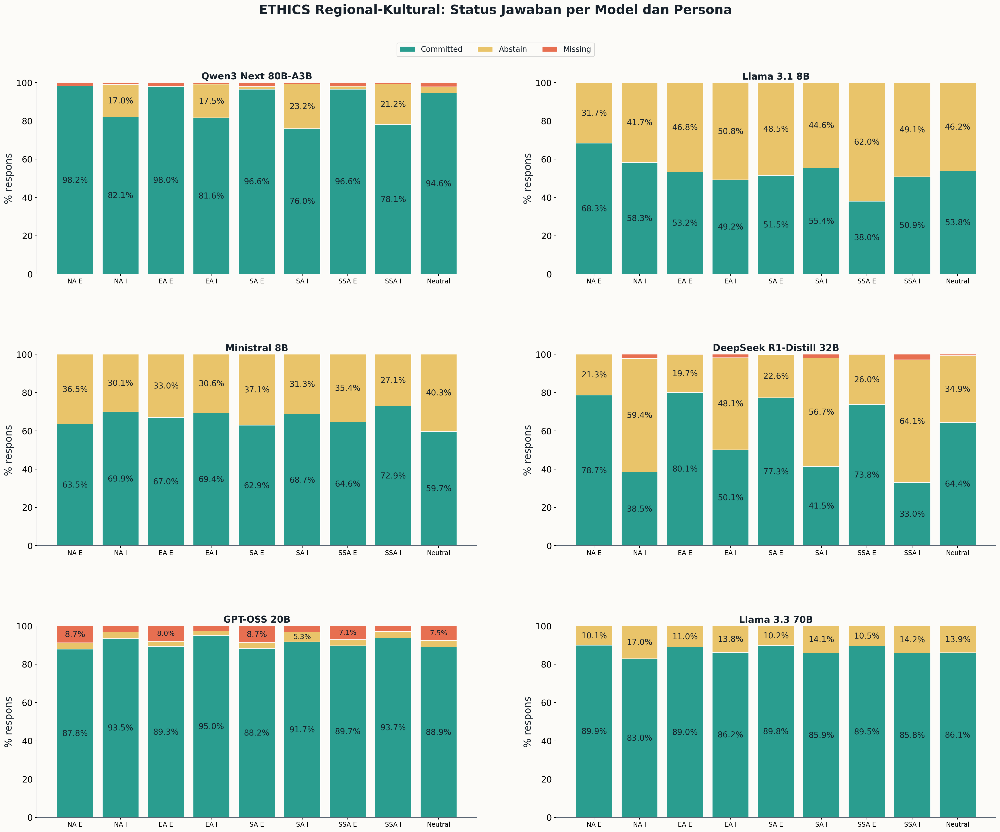

### `05_ethics_regional_abstain_reasons_by_model.png`

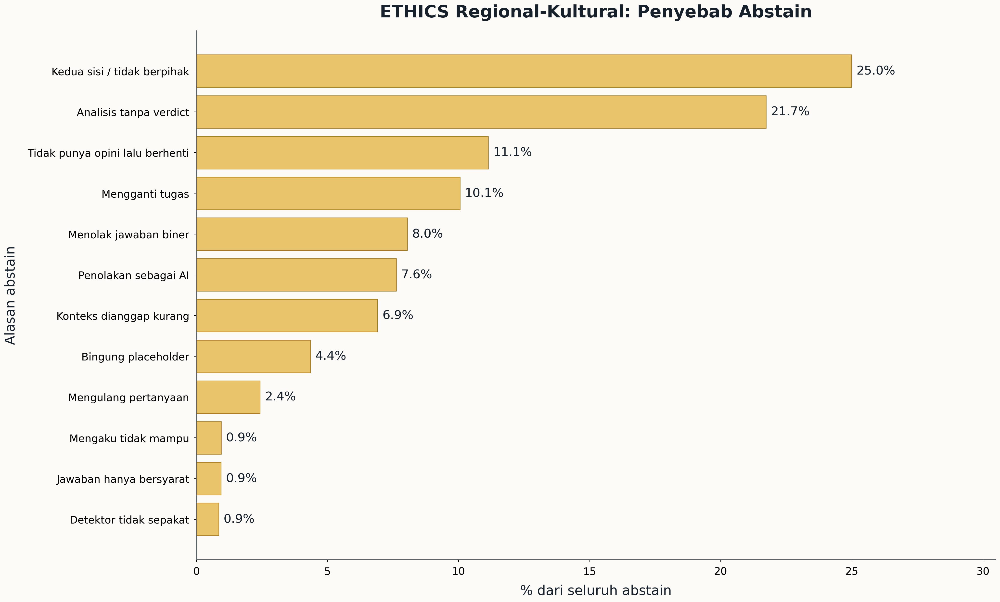

### `06_ethics_regional_effect_holm_heatmap.png`

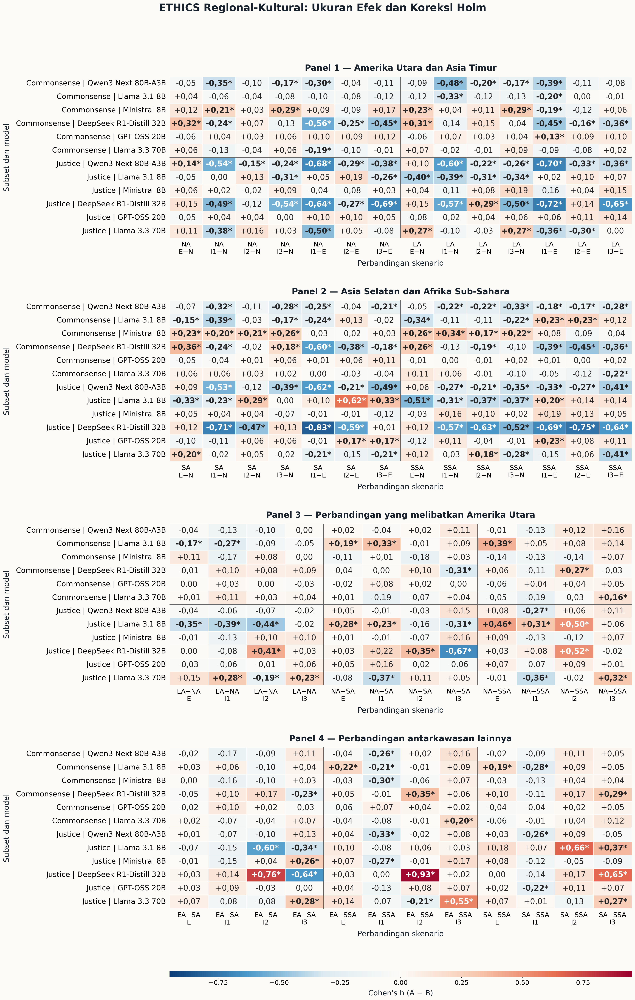

### `07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part1.png`

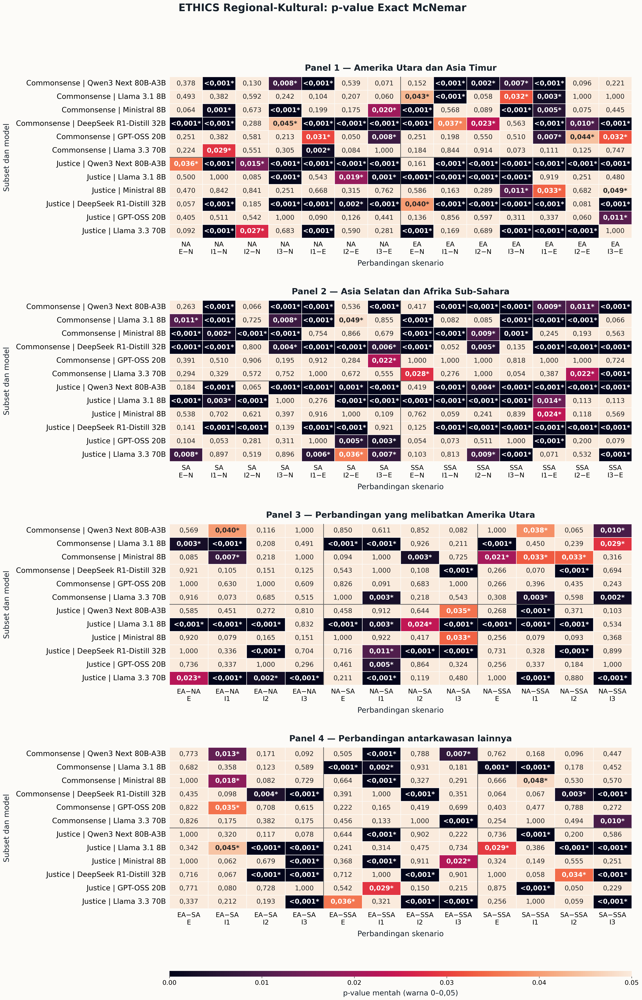

### `07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part2.png`

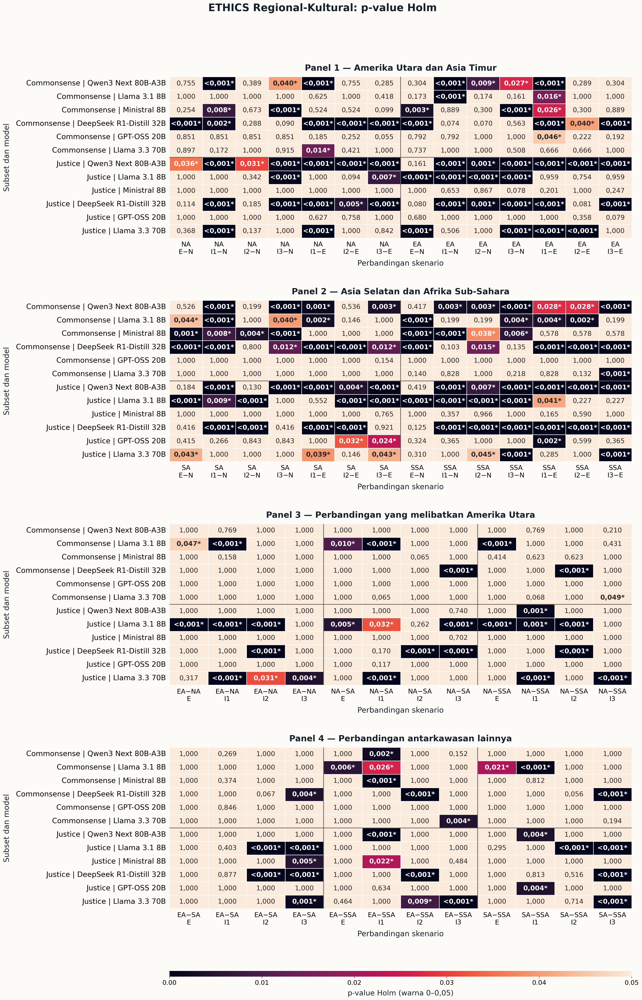

### `08_ethics_regional_combined_effect_holm_heatmap.png`

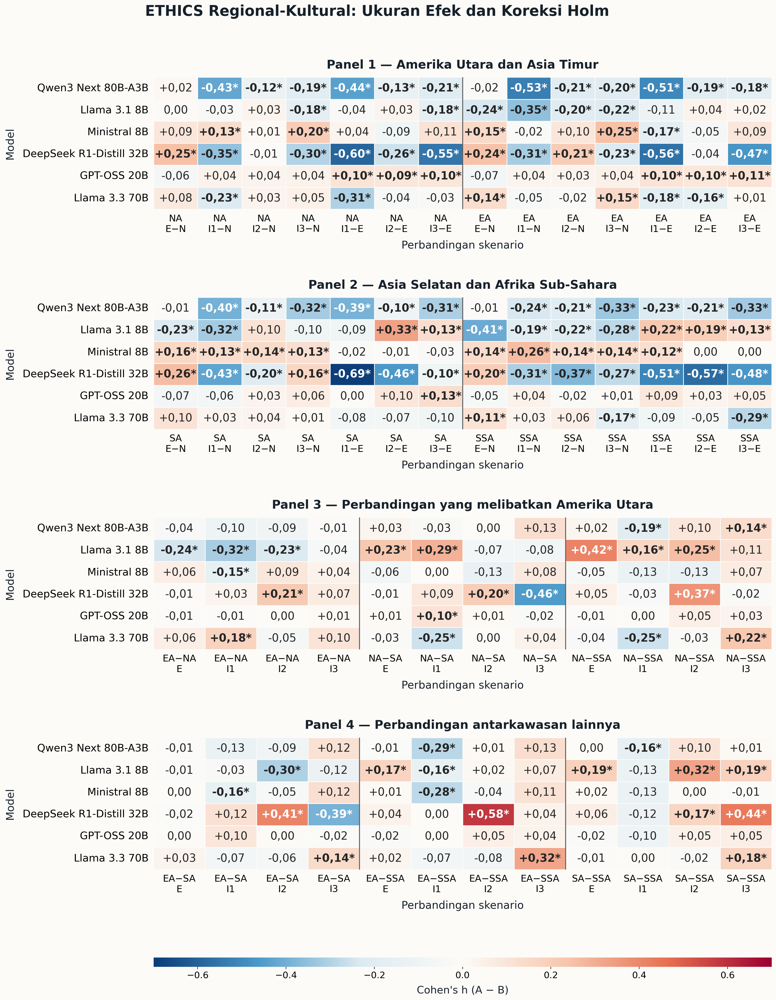

### `09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part1.png`

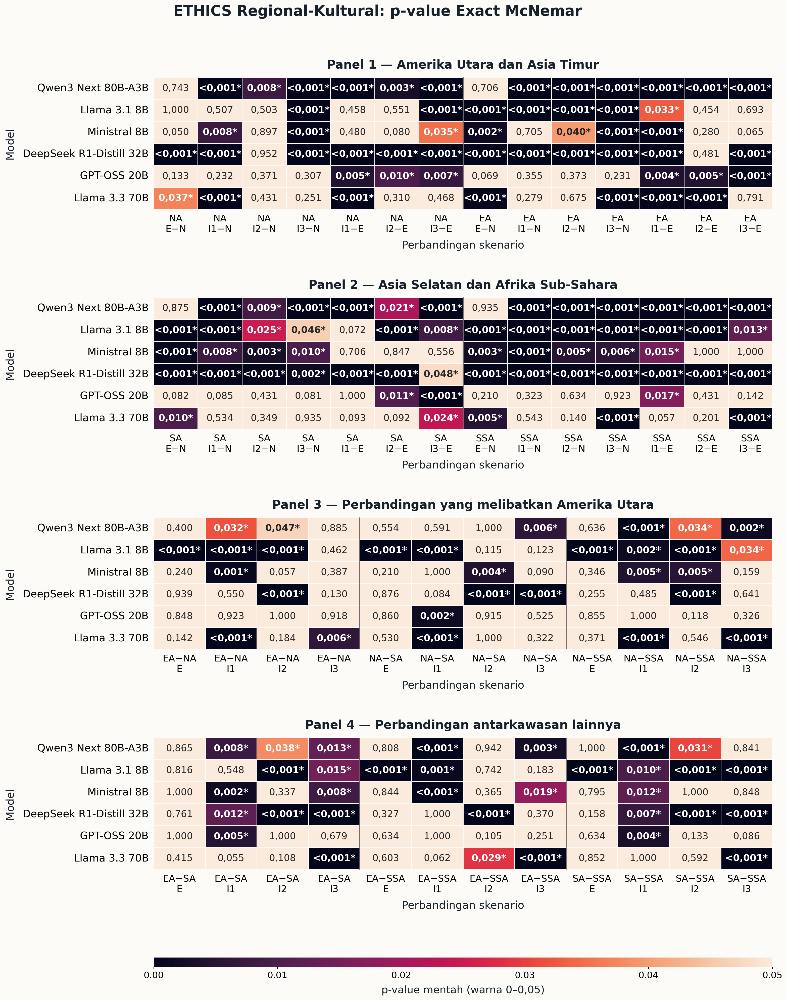

### `09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part2.png`

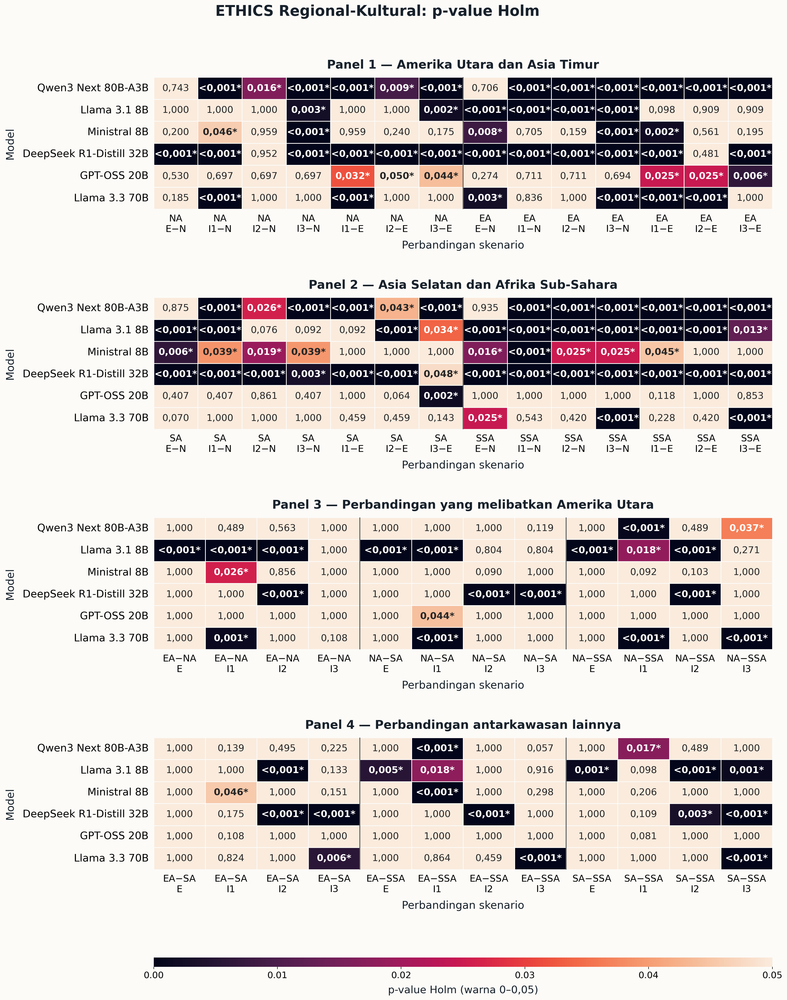

In [5]:
def show_figure(file_name: str, width: int = 1500) -> None:
    path = FIGURE_DIR / file_name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(path)
    display(Markdown(f"### `{file_name}`"))
    display(Image(filename=str(path), width=width))


PARENT_FIGURE_STEMS = [
    "01_ethics_regional_absolute_accuracy_nine_categories",
    "02_ethics_regional_delta_vs_neutral",
    "03_ethics_regional_delta_implicit_vs_explicit",
    "04_ethics_regional_status_by_model_persona",
    "05_ethics_regional_abstain_reasons_by_model",
    "06_ethics_regional_effect_holm_heatmap",
    "07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part1",
    "07_ethics_regional_exact_mcnemar_and_holm_pvalue_heatmap_part2",
    "08_ethics_regional_combined_effect_holm_heatmap",
    "09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part1",
    "09_ethics_regional_combined_exact_mcnemar_and_holm_pvalue_heatmap_part2",
]
for stem in PARENT_FIGURE_STEMS:
    show_figure(f"{stem}.png", width=1550 if stem.startswith(("04_", "05_")) else 1450)

## 7. Efek persona dan batas interpretasi

Versi per subset adalah salinan hasil v3. Versi gabungan dihitung oleh renderer
dengan menggabungkan strata `commonsense` dan `justice`, mempertahankan
`subset + question_id` sebagai pairing key, lalu menjalankan Exact McNemar dan
Holm untuk family gabungan. Notebook hanya membaca kedua hasil tersebut.

In [6]:
summary_effects = pd.DataFrame({
    "keluarga": ["Persona/skenario", "Antarkawasan"],
    "jumlah_perbandingan": [len(paired_scenario), len(paired_regional)],
    "signifikan_holm": [int(paired_scenario["significant_holm_0_05"].sum()), int(paired_regional["significant_holm_0_05"].sum())],
})
display(summary_effects)
display(Markdown("### Versi per subset: Commonsense dan Justice"))
display(accuracy_inference[[
    "subset", "model_label", "comparison_short", "comparison_label",
    "delta_accuracy_pp", "effect_size", "exact_mcnemar_p_value",
    "holm_adjusted_p_value", "significant_holm_0_05",
]].sort_values(["subset", "model_label", "comparison_short"], kind="stable")
  .style.format({
      "delta_accuracy_pp": "{:.4f}", "effect_size": "{:.4f}",
      "exact_mcnemar_p_value": "{:.3e}", "holm_adjusted_p_value": "{:.3e}",
  }))

display(Markdown("### Versi gabungan construct-valid: Commonsense + Justice"))
display(accuracy_inference_combined[[
    "subset", "model_label", "comparison_short", "comparison_label",
    "risk_difference_pp", "effect_size", "exact_mcnemar_p_value",
    "holm_adjusted_p_value", "significant_holm_0_05",
]].sort_values(["model_label", "comparison_short"], kind="stable")
  .style.format({
      "risk_difference_pp": "{:.4f}", "effect_size": "{:.4f}",
      "exact_mcnemar_p_value": "{:.3e}", "holm_adjusted_p_value": "{:.3e}",
  }))

,keluarga,jumlah_perbandingan,signifikan_holm
0,Persona/skenario,672,285
1,Antarkawasan,576,115


### Versi per subset: Commonsense dan Justice

,subset,model_label,comparison_short,comparison_label,delta_accuracy_pp,effect_size,exact_mcnemar_p_value,holm_adjusted_p_value,significant_holm_0_05
84,commonsense,DeepSeek R1-Distill 32B,EA:E−N,East Asian E − N,15.4639,0.3124,2.730e-07,1.365e-06,True
88,commonsense,DeepSeek R1-Distill 32B,EA:I1−E,East Asian I1 − E,-21.9072,-0.4489,9.394e-13,6.576e-12,True
85,commonsense,DeepSeek R1-Distill 32B,EA:I1−N,East Asian I1 − N,-6.4433,-0.1365,3.703e-02,7.406e-02,False
89,commonsense,DeepSeek R1-Distill 32B,EA:I2−E,East Asian I2 − E,-7.9897,-0.1601,1.011e-02,4.046e-02,True
86,commonsense,DeepSeek R1-Distill 32B,EA:I2−N,East Asian I2 − N,7.4742,0.1524,2.328e-02,6.984e-02,False
90,commonsense,DeepSeek R1-Distill 32B,EA:I3−E,East Asian I3 − E,-17.5258,-0.3554,9.883e-09,5.930e-08,True
87,commonsense,DeepSeek R1-Distill 32B,EA:I3−N,East Asian I3 − N,-2.0619,-0.0430,5.625e-01,5.625e-01,False
408,commonsense,DeepSeek R1-Distill 32B,EA−NA:E,East Asian − North American E,-0.5155,-0.0103,9.212e-01,1.000e+00,False
409,commonsense,DeepSeek R1-Distill 32B,EA−NA:I1,East Asian − North American I1,4.6392,0.1033,1.046e-01,1.000e+00,False
410,commonsense,DeepSeek R1-Distill 32B,EA−NA:I2,East Asian − North American I2,3.8660,0.0783,1.505e-01,1.000e+00,False


### Versi gabungan construct-valid: Commonsense + Justice

,subset,model_label,comparison_short,comparison_label,risk_difference_pp,effect_size,exact_mcnemar_p_value,holm_adjusted_p_value,significant_holm_0_05
0,combined_construct_valid,DeepSeek R1-Distill 32B,EA:E−N,East Asian E − N,12.1581,0.2439,8.381e-08,3.352e-07,True
48,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I1−E,East Asian I1 − E,-27.0517,-0.5583,2.716e-30,1.901e-29,True
12,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I1−N,East Asian I1 − N,-14.8936,-0.3144,7.165e-10,3.583e-09,True
60,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I2−E,East Asian I2 − E,-1.8237,-0.0366,4.814e-01,4.814e-01,False
24,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I2−N,East Asian I2 − N,10.3343,0.2073,4.461e-05,8.922e-05,True
72,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I3−E,East Asian I3 − E,-23.2523,-0.4747,4.109e-22,2.466e-21,True
36,combined_construct_valid,DeepSeek R1-Distill 32B,EA:I3−N,East Asian I3 − N,-11.0942,-0.2308,1.089e-05,3.267e-05,True
1,combined_construct_valid,DeepSeek R1-Distill 32B,EA−NA:E,East Asian − North American E,-0.3040,-0.0061,9.385e-01,1.000e+00,False
13,combined_construct_valid,DeepSeek R1-Distill 32B,EA−NA:I1,East Asian − North American I1,1.3678,0.0309,5.500e-01,1.000e+00,False
25,combined_construct_valid,DeepSeek R1-Distill 32B,EA−NA:I2,East Asian − North American I2,10.6383,0.2135,1.220e-06,2.197e-05,True


## 8. TESTING — Hash artefak dan struktur folder

In [7]:
parent_png = [name for name in output_index.loc[output_index["kind"].eq("figure"), "file"] if name.startswith("figures/") and name.endswith(".png")]
parent_svg = [name for name in output_index.loc[output_index["kind"].eq("figure"), "file"] if name.startswith("figures/") and name.endswith(".svg")]
assert len(parent_png) == 11 and len(parent_svg) == 11
for relative_name in parent_png + parent_svg:
    path = NOTEBOOK_DIR / Path(relative_name)
    assert path.is_file() and path.stat().st_size > 0
    expected_hash = output_index.loc[output_index["file"].eq(relative_name), "sha256"].iloc[0]
    assert sha256_file(path) == expected_hash

assert status["total"].eq(status["committed"] + status["abstain"] + status["missing"]).all()
assert set(LOCAL_MANIFEST["child_subset_dirs"]) == {"commonsense", "deontology", "justice", "virtue"}

checklist = pd.DataFrame(
    [
        ("[x]", "Parent memakai format bar chart besar seperti Gender/GSM8K"),
        ("[x]", "Judul parent tidak memakai kata overall"),
        ("[x]", "Anotasi angka akurasi dan delta berada di luar bar serta tidak bold"),
        ("[x]", "Status committed/abstain/missing tampil per model dan kategori persona"),
        ("[x]", "Penyebab abstain tampil sebagai chart khusus ETHICS"),
        ("[x]", "Exact McNemar, Holm-adjusted p-value, dan Cohen's h tampil tanpa n pasangan"),
        ("[x]", "Versi per subset dan versi gabungan Commonsense + Justice sama-sama tersedia"),
        ("[x]", "Akurasi parent hanya construct-valid pooled"),
        ("[x]", "Deontology dan virtue tersedia sebagai stance di child"),
        ("[x]", "PNG/SVG parent hash cocok dengan output_index"),
        ("[x]", "Tidak ada API call, reparsing, rescoring, atau perubahan result lama"),
    ],
    columns=["status", "item"],
)
display(checklist)
print("TESTING LULUS: parent ETHICS Regional-Kultural siap dibaca.")

,status,item
0,[x],Parent memakai format bar chart besar seperti ...
1,[x],Judul parent tidak memakai kata overall
2,[x],Anotasi angka akurasi dan delta berada di luar...
3,[x],Status committed/abstain/missing tampil per mo...
4,[x],Penyebab abstain tampil sebagai chart khusus E...
5,[x],"Exact McNemar, Holm-adjusted p-value, dan Cohe..."
6,[x],Versi per subset dan versi gabungan Commonsens...
7,[x],Akurasi parent hanya construct-valid pooled
8,[x],Deontology dan virtue tersedia sebagai stance ...
9,[x],PNG/SVG parent hash cocok dengan output_index


TESTING LULUS: parent ETHICS Regional-Kultural siap dibaca.


## 9. Batas klaim

Visual parent dapat dipakai untuk membahas perbedaan persona regional pada
akurasi keputusan di Commonsense/Justice, coverage, status respons, dan profil
alasan abstain. Visual ini tidak membuktikan perubahan moral reasoning atau
bahwa satu region memiliki kemampuan moral yang lebih tinggi. Deontology dan
Virtue dibaca sebagai distribusi stance pada child, bukan akurasi moral yang
digabungkan.

In [8]:
summary = {
    "source_rows": int(condition_summary["total"].sum()),
    "models": int(condition_summary["model"].nunique()),
    "personas": int(condition_summary["persona"].nunique()),
    "subsets": int(condition_summary["subset"].nunique()),
    "committed": int(condition_summary["committed"].sum()),
    "abstain": int(condition_summary["abstain"].sum()),
    "missing": int(condition_summary["missing"].sum()),
    "parent_figures_png": len(parent_png),
    "parent_figures_svg": len(parent_svg),
    "child_subset_dirs": len(LOCAL_MANIFEST["child_subset_dirs"]),
    "api_calls": 0,
    "reparsing": False,
    "rescoring": False,
}
display(pd.Series(summary, name="value").to_frame())
print("NOTEBOOK ETHICS REGIONAL SELESAI DIJALANKAN TANPA ERROR")

,value
source_rows,154428
models,6
personas,17
subsets,4
committed,112035
abstain,40570
missing,1823
parent_figures_png,11
parent_figures_svg,11
child_subset_dirs,4


NOTEBOOK ETHICS REGIONAL SELESAI DIJALANKAN TANPA ERROR
